In [1]:

print("Student Academic Performance Analysis")
print("Project ID: DA-003")
print("Let's analyze student performance!")


Student Academic Performance Analysis
Project ID: DA-003
Let's analyze student performance!


In [2]:

import pandas as pd

data = {
    "Student_ID": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Maths_Marks": [78, 45, 89, 56, 92, 34, 67, 81, 49, 73],
    "Science_Marks": [82, 50, 91, 60, 88, 40, 70, 85, 52, 76],
    "English_Marks": [75, 55, 84, 62, 90, 38, 72, 79, 48, 80],
    "Attendance": [90, 65, 95, 70, 98, 55, 80, 88, 60, 85],
    "Study_Hours": [3, 1, 4, 2, 5, 1, 3, 4, 2, 3]
}

df = pd.DataFrame(data)

print("Student Dataset:")
display(df)


Student Dataset:


,Student_ID,Maths_Marks,Science_Marks,English_Marks,Attendance,Study_Hours
0,1,78,82,75,90,3
1,2,45,50,55,65,1
2,3,89,91,84,95,4
3,4,56,60,62,70,2
4,5,92,88,90,98,5
5,6,34,40,38,55,1
6,7,67,70,72,80,3
7,8,81,85,79,88,4
8,9,49,52,48,60,2
9,10,73,76,80,85,3


In [3]:

# Step 3: Basic Statistical Analysis

# Calculate average (mean) marks
print("Mean Maths Marks:", df["Maths_Marks"].mean())
print("Mean Science Marks:", df["Science_Marks"].mean())
print("Mean English Marks:", df["English_Marks"].mean())

# Calculate median marks
print("\nMedian Maths Marks:", df["Maths_Marks"].median())
print("Median Science Marks:", df["Science_Marks"].median())
print("Median English Marks:", df["English_Marks"].median())

# Calculate pass percentage
passing_marks = 40

for subject in ["Maths_Marks", "Science_Marks", "English_Marks"]:
    passed = (df[subject] >= passing_marks).sum()
    total = len(df)
    pass_percentage = (passed / total) * 100

    print(subject, "Pass Percentage:", pass_percentage, "%")


Mean Maths Marks: 66.4
Mean Science Marks: 69.4
Mean English Marks: 68.3

Median Maths Marks: 70.0
Median Science Marks: 73.0
Median English Marks: 73.5
Maths_Marks Pass Percentage: 90.0 %
Science_Marks Pass Percentage: 100.0 %
English_Marks Pass Percentage: 90.0 %


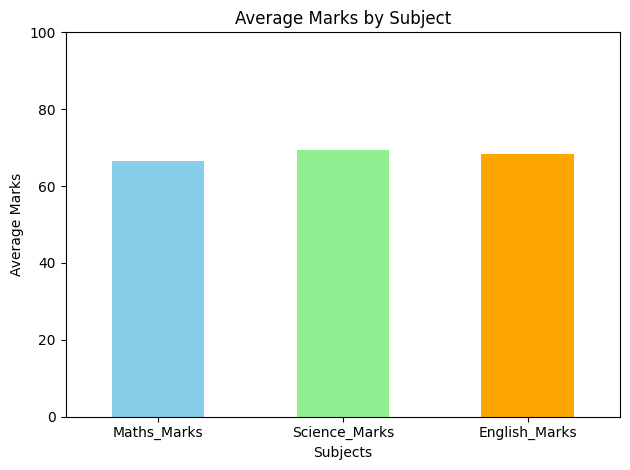

In [4]:

import matplotlib.pyplot as plt
import pandas as pd

# Calculate average marks for each subject
average_marks = df[["Maths_Marks", "Science_Marks", "English_Marks"]].mean()

# Create a bar chart
average_marks.plot(kind="bar", color=["skyblue", "lightgreen", "orange"])

plt.title("Average Marks by Subject")
plt.xlabel("Subjects")
plt.ylabel("Average Marks")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


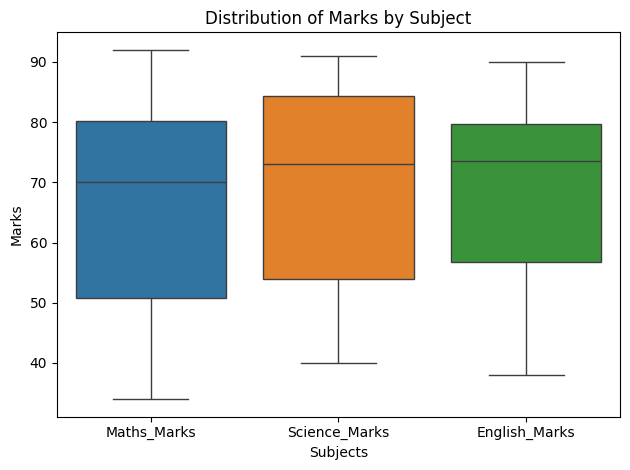

In [5]:

import seaborn as sns
import matplotlib.pyplot as plt

# Convert subject columns into a format suitable for plotting
marks_data = df[["Maths_Marks", "Science_Marks", "English_Marks"]]

sns.boxplot(data=marks_data)
plt.title("Distribution of Marks by Subject")
plt.xlabel("Subjects")
plt.ylabel("Marks")
plt.tight_layout()
plt.show()


In [6]:

# Step 5: Correlation Analysis

# Calculate each student's average marks across all subjects
df["Average_Marks"] = df[
    ["Maths_Marks", "Science_Marks", "English_Marks"]
].mean(axis=1)

# Calculate correlation coefficients
attendance_corr = df["Attendance"].corr(df["Average_Marks"])
study_corr = df["Study_Hours"].corr(df["Average_Marks"])

print("Attendance vs Average Marks:", round(attendance_corr, 2))
print("Study Hours vs Average Marks:", round(study_corr, 2))


Attendance vs Average Marks: 0.99
Study Hours vs Average Marks: 0.95


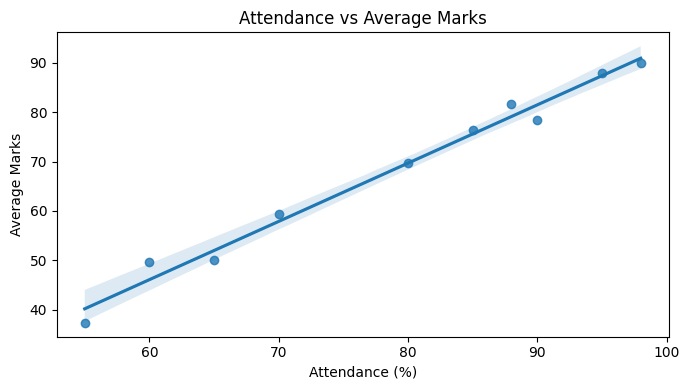

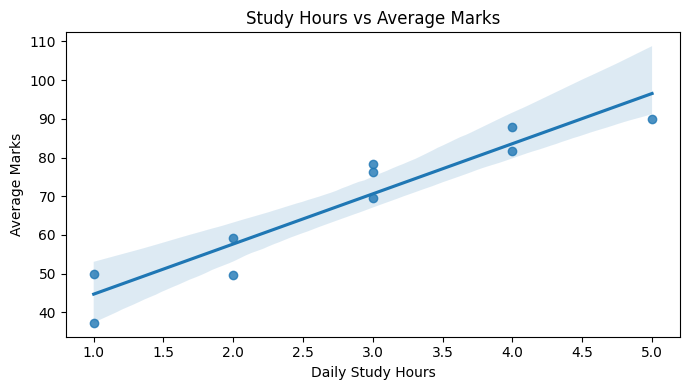

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

# Plot 1: Attendance vs marks
plt.figure(figsize=(7, 4))
sns.regplot(data=df, x="Attendance", y="Average_Marks")
plt.title("Attendance vs Average Marks")
plt.xlabel("Attendance (%)")
plt.ylabel("Average Marks")
plt.tight_layout()
plt.show()

# Plot 2: Study hours vs marks
plt.figure(figsize=(7, 4))
sns.regplot(data=df, x="Study_Hours", y="Average_Marks")
plt.title("Study Hours vs Average Marks")
plt.xlabel("Daily Study Hours")
plt.ylabel("Average Marks")
plt.tight_layout()
plt.show()


In [8]:

# Step 6: Data Cleaning

# Make a copy so the original data stays unchanged
df_clean = df.copy()

# Check missing values
print("Missing values before cleaning:")
print(df_clean.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df_clean.duplicated().sum())

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Fill missing numerical values with their column median
numeric_cols = df_clean.select_dtypes(include="number").columns

df_clean[numeric_cols] = df_clean[numeric_cols].fillna(
    df_clean[numeric_cols].median()
)

# Check reasonable value ranges
mark_cols = ["Maths_Marks", "Science_Marks", "English_Marks"]

for col in mark_cols:
    print(col, "invalid marks:",
          ((df_clean[col] < 0) | (df_clean[col] > 100)).sum())

print("Invalid attendance values:",
      ((df_clean["Attendance"] < 0) |
       (df_clean["Attendance"] > 100)).sum())

print("Invalid study hours:",
      (df_clean["Study_Hours"] < 0).sum())

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())


Missing values before cleaning:
Student_ID       0
Maths_Marks      0
Science_Marks    0
English_Marks    0
Attendance       0
Study_Hours      0
Average_Marks    0
dtype: int64

Duplicate rows: 0
Maths_Marks invalid marks: 0
Science_Marks invalid marks: 0
English_Marks invalid marks: 0
Invalid attendance values: 0
Invalid study hours: 0

Missing values after cleaning:
Student_ID       0
Maths_Marks      0
Science_Marks    0
English_Marks    0
Attendance       0
Study_Hours      0
Average_Marks    0
dtype: int64


SUBJECT-WISE PERFORMANCE


,Mean,Median,Pass_Percentage
Maths,66.4,70.0,90.0
Science,69.4,73.0,100.0
English,68.3,73.5,90.0



OVERALL SUMMARY
Number of student records: 10
Overall average marks: 68.03
Average attendance (%): 78.6
Average daily study hours: 2.8

CORRELATION RESULTS
Attendance vs marks: 0.99
Study hours vs marks: 0.95


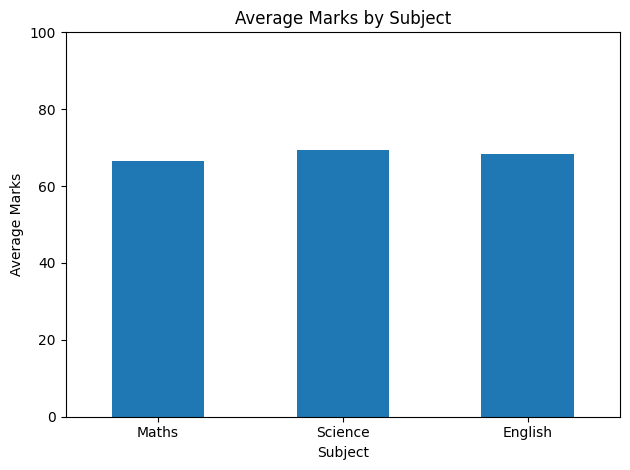

In [9]:

# Step 7: Final Summary and Recommendations

import pandas as pd
import matplotlib.pyplot as plt

# Use the cleaned dataset
subjects = ["Maths_Marks", "Science_Marks", "English_Marks"]

# Calculate subject-wise summary
summary = pd.DataFrame({
    "Mean": df_clean[subjects].mean(),
    "Median": df_clean[subjects].median(),
    "Pass_Percentage": [
        (df_clean[s] >= 40).mean() * 100 for s in subjects
    ]
})

summary.index = ["Maths", "Science", "English"]

print("SUBJECT-WISE PERFORMANCE")
display(summary.round(2))

# Overall student performance
df_clean["Average_Marks"] = df_clean[subjects].mean(axis=1)

print("\nOVERALL SUMMARY")
print("Number of student records:", len(df_clean))
print("Overall average marks:",
      round(df_clean["Average_Marks"].mean(), 2))
print("Average attendance (%):",
      round(df_clean["Attendance"].mean(), 2))
print("Average daily study hours:",
      round(df_clean["Study_Hours"].mean(), 2))

# Correlation analysis
print("\nCORRELATION RESULTS")
print("Attendance vs marks:",
      round(df_clean["Attendance"].corr(
          df_clean["Average_Marks"]), 2))
print("Study hours vs marks:",
      round(df_clean["Study_Hours"].corr(
          df_clean["Average_Marks"]), 2))

# Compare average marks visually
summary["Mean"].plot(kind="bar", title="Average Marks by Subject")
plt.ylabel("Average Marks")
plt.xlabel("Subject")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
